# Charged-Particle Motion in a Uniform Magnetic Field

Numerical investigation of charged-particle motion under the Lorentz force using Python, NumPy, SciPy, and Matplotlib.

## 1. Introduction

This project investigates the motion of a charged particle in a uniform magnetic field. The electric field is set to zero, while the magnetic field is taken to be uniform and directed along the z-axis.

The motion is obtained by numerically solving the equation of motion and visualizing the resulting trajectory in three dimensions. The main goal is to examine how the particle trajectory changes with its initial velocity, charge-to-mass ratio, and magnetic-field strength.

## 2. Physical Model and Theoretical Background

The motion of a charged particle in an electromagnetic field is described by the Lorentz force:

$$
\mathbf{F} = q(\mathbf{E} + \mathbf{v} \times \mathbf{B}).
$$

In this project, the electric field is set to zero:

$$
\mathbf{E} = 0,
$$

and the magnetic field is uniform and directed along the z-axis:

$$
\mathbf{B} = (0,0,B).
$$

Therefore, the equation of motion becomes:

$$
m\frac{d\mathbf{v}}{dt}
= q(\mathbf{v}\times\mathbf{B}).
$$

Here, \(m\) is the particle's mass, \(q\) is its electric charge, \(\mathbf{v}\) is its velocity, and \(\mathbf{B}\) is the magnetic field.

The magnetic force is always perpendicular to the particle's velocity. As a result, it changes the direction of motion but does not change the particle's speed. For a magnetic field directed along the z-axis, the velocity component parallel to the field remains constant, while the perpendicular components rotate in the xy-plane.

If the initial velocity has no component parallel to the magnetic field, so that \(v_z = 0\), the particle follows a circular trajectory. If \(v_z \neq 0\), the particle moves along the field while rotating around it, producing a helical trajectory.

The radius of the circular motion, known as the Larmor radius, is

$$
r_L = \frac{m v_\perp}{|q|B},
$$

where \(v_\perp\) is the magnitude of the velocity perpendicular to the field. For fixed mass, charge, and perpendicular speed, increasing the magnetic-field strength decreases the radius. Reversing the sign of the charge reverses the direction of rotation.

## 3. Equations of Motion

Let the velocity and magnetic field be

$$
\mathbf{v} = (v_x,v_y,v_z),
$$

and

$$
\mathbf{B} = (0,0,B).
$$

Their cross product is

$$
\mathbf{v}\times\mathbf{B}
=
(v_yB,-v_xB,0).
$$

Therefore, the equations of motion are

$$
\frac{dv_x}{dt} = \frac{q}{m}Bv_y,
$$

$$
\frac{dv_y}{dt} = -\frac{q}{m}Bv_x,
$$

$$
\frac{dv_z}{dt} = 0.
$$

The position is obtained from the velocity according to

$$
\frac{dx}{dt}=v_x,\qquad
\frac{dy}{dt}=v_y,\qquad
\frac{dz}{dt}=v_z.
$$

These six first-order differential equations will be solved numerically using `scipy.integrate.solve_ivp`.

## 4. Numerical Solution

The equations of motion can be written as a system of six first-order differential equations for the position and velocity components.

We use `scipy.integrate.solve_ivp` to solve this system numerically. The state vector is defined as

$$
\mathbf{y} = (x,y,z,v_x,v_y,v_z).
$$

For given values of \(q/m\), \(B\), and the initial conditions, the solver returns the particle position and velocity as functions of time.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


def equations_of_motion(t, state, q_over_m, B):
    x, y, z, vx, vy, vz = state

    dxdt = vx
    dydt = vy
    dzdt = vz

    dvxdt = q_over_m * B * vy
    dvydt = -q_over_m * B * vx
    dvzdt = 0.0

    return [dxdt, dydt, dzdt, dvxdt, dvydt, dvzdt]


# Physical parameters
q_over_m = 1.0
B = 1.0

# Initial position
r0 = [0.0, 0.0, 0.0]

# Initial velocity
v0 = [1.0, 0.0, 0.0]

# Initial state
initial_state = r0 + v0

# Time interval
t_start = 0.0
t_end = 20.0
num_points = 1000

t_eval = np.linspace(t_start, t_end, num_points)

solution = solve_ivp(
    equations_of_motion,
    (t_start, t_end),
    initial_state,
    args=(q_over_m, B),
    t_eval=t_eval
)

print("Solution successful:", solution.success)

Solution successful: True


## 5. Case 1 — Circular Motion

For the first case, the initial velocity has no component along the magnetic field:

$$
v_z = 0.
$$

Therefore, the particle is expected to move in a circular trajectory in the xy-plane.

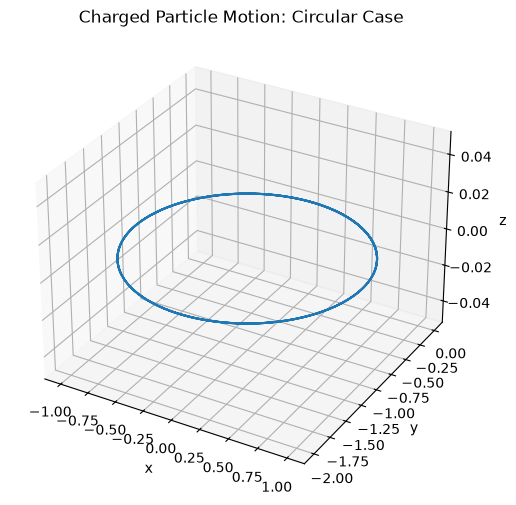

In [2]:
x = solution.y[0]
y = solution.y[1]
z = solution.y[2]

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.plot(x, y, z)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Charged Particle Motion: Circular Case")

plt.show()

## 6. Case 2 — Helical Motion

For the second case, the particle has a nonzero velocity component along the magnetic field:

$$
v_z \neq 0.
$$

The motion in the xy-plane remains circular, while the particle moves uniformly along the z-direction. The resulting trajectory is therefore helical.

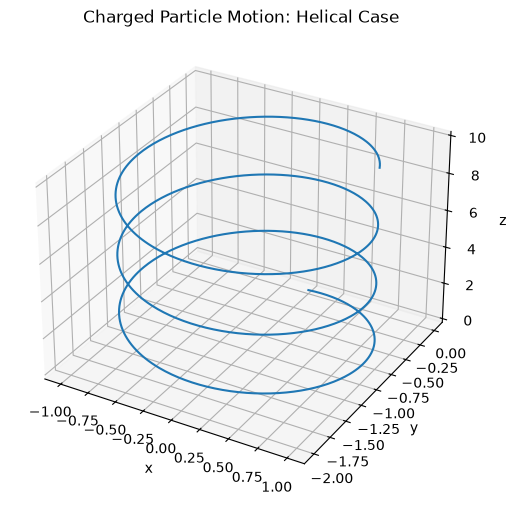

In [3]:
# Initial velocity for helical motion
v0_helix = [1.0, 0.0, 0.5]

# Initial state
initial_state_helix = r0 + v0_helix

# Solve the equations
solution_helix = solve_ivp(
    equations_of_motion,
    (t_start, t_end),
    initial_state_helix,
    args=(q_over_m, B),
    t_eval=t_eval
)

x_helix = solution_helix.y[0]
y_helix = solution_helix.y[1]
z_helix = solution_helix.y[2]

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.plot(x_helix, y_helix, z_helix)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Charged Particle Motion: Helical Case")

plt.show()

## 7. Effect of Charge-to-Mass Ratio

The sign of the charge-to-mass ratio affects the direction of rotation of the particle.

To examine this effect, we compare the trajectories for positive and negative values of \(q/m\), while keeping the magnetic field and initial velocity unchanged.

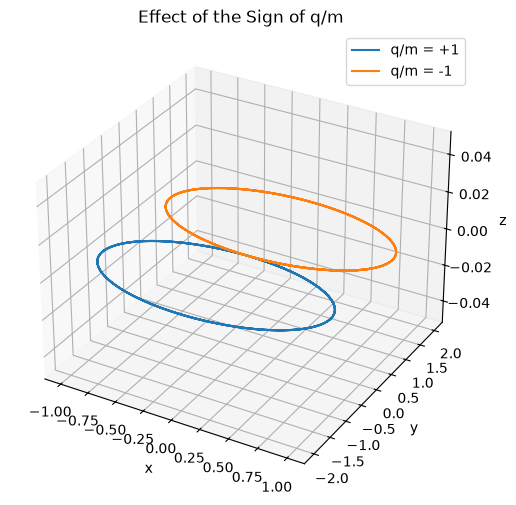

In [4]:
q_over_m_positive = 1.0
q_over_m_negative = -1.0

initial_state = [0.0, 0.0, 0.0, 1.0, 0.0, 0.0]

solution_positive = solve_ivp(
    equations_of_motion,
    (t_start, t_end),
    initial_state,
    args=(q_over_m_positive, B),
    t_eval=t_eval
)

solution_negative = solve_ivp(
    equations_of_motion,
    (t_start, t_end),
    initial_state,
    args=(q_over_m_negative, B),
    t_eval=t_eval
)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    solution_positive.y[0],
    solution_positive.y[1],
    solution_positive.y[2],
    label="q/m = +1"
)

ax.plot(
    solution_negative.y[0],
    solution_negative.y[1],
    solution_negative.y[2],
    label="q/m = -1"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Effect of the Sign of q/m")
ax.legend()

plt.show()

## 8. Effect of Magnetic Field Strength

The magnetic-field strength affects the radius of the circular motion.

For a fixed charge-to-mass ratio and initial velocity, increasing the magnetic-field strength increases the rate of rotation and decreases the radius of the trajectory.

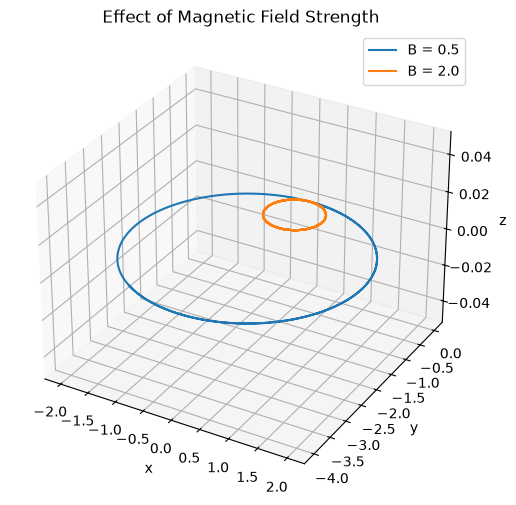

In [5]:
B_weak = 0.5
B_strong = 2.0

initial_state = [0.0, 0.0, 0.0, 1.0, 0.0, 0.0]

solution_weak = solve_ivp(
    equations_of_motion,
    (t_start, t_end),
    initial_state,
    args=(q_over_m, B_weak),
    t_eval=t_eval
)

solution_strong = solve_ivp(
    equations_of_motion,
    (t_start, t_end),
    initial_state,
    args=(q_over_m, B_strong),
    t_eval=t_eval
)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    solution_weak.y[0],
    solution_weak.y[1],
    solution_weak.y[2],
    label="B = 0.5"
)

ax.plot(
    solution_strong.y[0],
    solution_strong.y[1],
    solution_strong.y[2],
    label="B = 2.0"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Effect of Magnetic Field Strength")
ax.legend()

plt.show()

## 9. Discussion

The numerical results reproduce the expected behavior of a charged particle in a uniform magnetic field.

When the initial velocity is perpendicular to the magnetic field, the particle follows a circular trajectory in the xy-plane. When a nonzero velocity component is added along the magnetic field, the trajectory becomes helical.

Changing the sign of \(q/m\) reverses the direction of rotation, while increasing the magnetic-field strength decreases the radius of the circular motion.

These results show that the numerical solution is consistent with the qualitative behavior expected from the Lorentz force.

## 10. Limitations

This model has several limitations:

1. The electric field is neglected and the magnetic field is assumed to be uniform and constant in time. Therefore, the model does not describe more general electromagnetic configurations.

2. The equations are based on the classical nonrelativistic Lorentz force. At sufficiently high particle velocities, relativistic effects would need to be taken into account.